<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# Procesamiento de lenguaje natural
## Custom embedddings con Gensim

**Estudiante:** a2517 - Gabriela Di Grazia

**Docente:** Josselyn Ordóñez

**Desafío 2**


### Objetivo
El objetivo es utilizar documentos / corpus para crear embeddings de palabras basado en ese contexto. Se utilizará canciones de bandas para generar los embeddings, es decir, que los vectores tendrán la forma en función de como esa banda haya utilizado las palabras en sus canciones.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import multiprocessing
try:
  from gensim.models import Word2Vec
except:
  !pip install gensim
  from gensim.models import Word2Vec

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 37.3 MB/s eta 0:00:00


### Datos
Utilizaremos como dataset canciones de bandas de habla inglesa.

In [2]:
# Descargar la carpeta de dataset
import os
import platform
if os.access('./songs_dataset', os.F_OK) is False:
    if os.access('songs_dataset.zip', os.F_OK) is False:
        if platform.system() == 'Windows':
            !curl https://raw.githubusercontent.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/main/datasets/songs_dataset.zip -o songs_dataset.zip
        else:
            !wget songs_dataset.zip https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/raw/main/datasets/songs_dataset.zip
    !unzip -q songs_dataset.zip
else:
    print("El dataset ya se encuentra descargado")

--2026-09-16 19:56:26--  http://songs_dataset.zip/
Resolving songs_dataset.zip (songs_dataset.zip)... failed: Name or service not known.
wget: unable to resolve host address ‘songs_dataset.zip’
--2026-09-16 19:56:26--  https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/raw/main/datasets/songs_dataset.zip
Resolving github.com (github.com)... 20.29.134.23
Connecting to github.com (github.com)|20.29.134.23|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/main/datasets/songs_dataset.zip [following]
--2026-09-16 19:56:27--  https://raw.githubusercontent.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/main/datasets/songs_dataset.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.

In [3]:
# Posibles bandas
os.listdir("./songs_dataset/")

['amy-winehouse.txt',
 'lorde.txt',
 'nirvana.txt',
 'nicki-minaj.txt',
 'britney-spears.txt',
 'disney.txt',
 'Kanye_West.txt',
 'bruce-springsteen.txt',
 'michael-jackson.txt',
 'eminem.txt',
 'jimi-hendrix.txt',
 'dickinson.txt',
 'Lil_Wayne.txt',
 'radiohead.txt',
 'missy-elliott.txt',
 'drake.txt',
 'beatles.txt',
 'lin-manuel-miranda.txt',
 'cake.txt',
 'dr-seuss.txt',
 'notorious-big.txt',
 'kanye-west.txt',
 'lil-wayne.txt',
 'nickelback.txt',
 'bruno-mars.txt',
 'notorious_big.txt',
 'bob-dylan.txt',
 'patti-smith.txt',
 'prince.txt',
 'dj-khaled.txt',
 'dolly-parton.txt',
 'paul-simon.txt',
 'bieber.txt',
 'joni-mitchell.txt',
 'alicia-keys.txt',
 'blink-182.txt',
 'bjork.txt',
 'bob-marley.txt',
 'nursery_rhymes.txt',
 'johnny-cash.txt',
 'leonard-cohen.txt',
 'adele.txt',
 'janisjoplin.txt',
 'ludacris.txt',
 'rihanna.txt',
 'al-green.txt',
 'kanye.txt',
 'r-kelly.txt',
 'lady-gaga.txt']

In [4]:
# Armar el dataset utilizando salto de línea para separar las oraciones/docs
df = pd.read_csv('songs_dataset/beatles.txt', sep='/n', header=None)
df.head()

/tmp/ipykernel_1416/3849064916.py:2: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv('songs_dataset/beatles.txt', sep='/n', header=None)


,0
0,"Yesterday, all my troubles seemed so far away"
1,Now it looks as though they're here to stay
2,"Oh, I believe in yesterday Suddenly, I'm not h..."
3,There's a shadow hanging over me.
4,"Oh, yesterday came suddenly Why she had to go ..."


In [5]:
print("Cantidad de documentos:", df.shape[0])

Cantidad de documentos: 1846


### 1 - Preprocesamiento

In [6]:
try:
    from tensorflow.keras.preprocessing.text import text_to_word_sequence
except Exception:
    from gensim.utils import simple_preprocess
    def text_to_word_sequence(text):
        return simple_preprocess(str(text), deacc=True)

sentence_tokens = []
# Recorrer todas las filas y transformar las oraciones
# en una secuencia de palabras (esto podría realizarse con NLTK o spaCy también)
for _, row in df[:None].iterrows():
    sentence_tokens.append(text_to_word_sequence(row[0]))

In [7]:
# Demos un vistazo
sentence_tokens[:2]

[['yesterday', 'all', 'my', 'troubles', 'seemed', 'so', 'far', 'away'],
 ['now', 'it', 'looks', 'as', 'though', "they're", 'here', 'to', 'stay']]

### 2 - Crear los vectores (word2vec)

In [8]:
from gensim.models.callbacks import CallbackAny2Vec
# Durante el entrenamiento gensim por defecto no informa el "loss" en cada época
# Sobrecargamos el callback para poder tener esta información
class callback(CallbackAny2Vec):
    """
    Callback to print loss after each epoch
    """
    def __init__(self):
        self.epoch = 0

    def on_epoch_end(self, model):
        loss = model.get_latest_training_loss()
        if self.epoch == 0:
            print('Loss after epoch {}: {}'.format(self.epoch, loss))
        else:
            print('Loss after epoch {}: {}'.format(self.epoch, loss- self.loss_previous_step))
        self.epoch += 1
        self.loss_previous_step = loss

In [9]:
# Crearmos el modelo generador de vectores
# En este caso utilizaremos la estructura modelo Skipgram
w2v_model = Word2Vec(min_count=5,    # frecuencia mínima de palabra para incluirla en el vocabulario
                     window=2,       # cant de palabras antes y desp de la predicha
                     vector_size=300,       # dimensionalidad de los vectores
                     negative=20,    # cantidad de negative samples... 0 es no se usa
                     workers=1,      # si tienen más cores pueden cambiar este valor
                     sg=1)           # modelo 0:CBOW  1:skipgram

In [10]:
# Obtener el vocabulario con los tokens
w2v_model.build_vocab(sentence_tokens)

In [11]:
# Cantidad de filas/docs encontradas en el corpus
print("Cantidad de docs en el corpus:", w2v_model.corpus_count)

Cantidad de docs en el corpus: 1846


In [12]:
# Cantidad de words encontradas en el corpus
print("Cantidad de words distintas en el corpus:", len(w2v_model.wv.index_to_key))

Cantidad de words distintas en el corpus: 445


### 3 - Entrenar embeddings

In [13]:
# Entrenamos el modelo generador de vectores
# Utilizamos nuestro callback
w2v_model.train(sentence_tokens,
                 total_examples=w2v_model.corpus_count,
                 epochs=20,
                 compute_loss = True,
                 callbacks=[callback()]
                 )

Loss after epoch 0: 113045.25
Loss after epoch 1: 65966.59375
Loss after epoch 2: 65934.984375
Loss after epoch 3: 65718.390625
Loss after epoch 4: 63875.09375
Loss after epoch 5: 64160.65625
Loss after epoch 6: 64080.21875
Loss after epoch 7: 64814.875
Loss after epoch 8: 62632.75
Loss after epoch 9: 60452.875
Loss after epoch 10: 59839.875
Loss after epoch 11: 58884.375
Loss after epoch 12: 57715.75
Loss after epoch 13: 56494.3125
Loss after epoch 14: 55817.5
Loss after epoch 15: 55842.9375
Loss after epoch 16: 51722.4375
Loss after epoch 17: 49858.0
Loss after epoch 18: 49592.25
Loss after epoch 19: 48960.125


(156986, 287740)

### 4 - Ensayar

In [14]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["darling"], topn=10)

[('pretty', 0.8954247832298279),
 ('sleep', 0.8665655851364136),
 ('help', 0.8439376354217529),
 ('cry', 0.8351269960403442),
 ('not', 0.8309612274169922),
 ('try', 0.8276943564414978),
 ('peace', 0.8144856691360474),
 ('little', 0.8140572309494019),
 ('twist', 0.8123919367790222),
 ('seems', 0.8079564571380615)]

In [15]:
# Palabras que MENOS se relacionan con...:
w2v_model.wv.most_similar(negative=["love"], topn=10)

[('shake', -0.22873197495937347),
 ('four', -0.2330218255519867),
 ('five', -0.23746445775032043),
 ('six', -0.23784494400024414),
 ('bang', -0.24832050502300262),
 ('our', -0.25539135932922363),
 ('day', -0.2689811885356903),
 ('going', -0.2692062556743622),
 ('here', -0.26990723609924316),
 ('three', -0.2838989198207855)]

In [16]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["four"], topn=10)

[('five', 0.9813723564147949),
 ('three', 0.9745770692825317),
 ('six', 0.9710808992385864),
 ('seven', 0.9584357738494873),
 ('two', 0.9517216682434082),
 ('sixty', 0.8990395665168762),
 ('one', 0.7951181530952454),
 ('crying', 0.7946289777755737),
 ('us', 0.7740051746368408),
 ("i'm", 0.7508383393287659)]

In [17]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["money"], topn=5)

[("can't", 0.9434017539024353),
 ('buy', 0.9396998882293701),
 ('much', 0.9033146500587463),
 ('just', 0.8509082198143005),
 ('hide', 0.835538387298584)]

In [18]:
# Ensayar con una palabra que no está en el vocabulario:
w2v_model.wv.most_similar(negative=["diedaa"])

KeyError: "Key 'diedaa' not present in vocabulary"

In [19]:
# el método `get_vector` permite obtener los vectores:
vector_love = w2v_model.wv.get_vector("love")
print(vector_love)

[ 0.06138203  0.05881222 -0.06370417  0.02444947 -0.20152196 -0.18612292
 -0.15284595  0.4548753  -0.04217871  0.03536078  0.13657516 -0.18520005
 -0.1812647   0.22149836 -0.3038084  -0.23970386  0.07094695 -0.05679139
 -0.05166207 -0.23843557 -0.08530281  0.19564727 -0.07678778  0.03797247
  0.07517307 -0.04826551  0.07379535  0.10396848  0.00738022 -0.22764729
 -0.0456724   0.12937619  0.27785638  0.19387618 -0.13509148  0.20857106
  0.40917322 -0.00387122 -0.1063128  -0.09056759  0.02400028 -0.0800491
  0.13400665  0.08833536 -0.01894405  0.08592905 -0.15905626  0.10259357
  0.14459287 -0.12092585 -0.27919102 -0.04061577  0.11382084  0.31365854
 -0.07409792  0.13976744  0.22791271  0.13209458 -0.01811365  0.09772275
  0.09249583 -0.14871688 -0.16348091 -0.13203284 -0.09834065  0.02714608
  0.16531324  0.26051944 -0.0325964  -0.02894551  0.11621328 -0.06974234
  0.09563565 -0.15276384  0.22071053  0.15996666  0.1589048  -0.04711676
 -0.12555045 -0.03993924 -0.10795183  0.01878959  0.

In [20]:
# el método `most_similar` también permite comparar a partir de vectores
w2v_model.wv.most_similar(vector_love)

[('love', 0.9999999403953552),
 ('babe', 0.9085132479667664),
 ('someone', 0.8886148929595947),
 ('need', 0.8827974200248718),
 ('nothing', 0.8740269541740417),
 ("didn't", 0.8638361096382141),
 ("there's", 0.8526672720909119),
 ('you', 0.8456704616546631),
 ('feed', 0.8445017337799072),
 ('somebody', 0.8362804651260376)]

In [21]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["love"], topn=10)

[('babe', 0.9085132479667664),
 ('someone', 0.8886148929595947),
 ('need', 0.8827974200248718),
 ('nothing', 0.8740269541740417),
 ("didn't", 0.8638360500335693),
 ("there's", 0.8526672720909119),
 ('you', 0.8456703424453735),
 ('feed', 0.8445016741752625),
 ('somebody', 0.8362804651260376),
 ('buy', 0.8351694941520691)]

### 5 - Visualizar agrupación de vectores

In [22]:
from sklearn.decomposition import IncrementalPCA
from sklearn.manifold import TSNE
import numpy as np

def reduce_dimensions(model, num_dimensions = 2 ):

    vectors = np.asarray(model.wv.vectors)
    labels = np.asarray(model.wv.index_to_key)

    tsne = TSNE(n_components=num_dimensions, random_state=0)
    vectors = tsne.fit_transform(vectors)

    return vectors, labels

In [23]:
# Graficar los embedddings en 2D
import plotly.graph_objects as go
import plotly.express as px

vecs, labels = reduce_dimensions(w2v_model)

MAX_WORDS=200
fig = px.scatter(x=vecs[:MAX_WORDS,0], y=vecs[:MAX_WORDS,1], text=labels[:MAX_WORDS])
fig.show(renderer="colab") # esto para plotly en colab

In [24]:
# Graficar los embedddings en 3D

vecs, labels = reduce_dimensions(w2v_model,3)

fig = px.scatter_3d(x=vecs[:MAX_WORDS,0], y=vecs[:MAX_WORDS,1], z=vecs[:MAX_WORDS,2],text=labels[:MAX_WORDS])
fig.update_traces(marker_size = 2)
fig.show(renderer="colab") # esto para plotly en colab

In [25]:
# También se pueden guardar los vectores y labels como tsv para graficar en
# http://projector.tensorflow.org/


vectors = np.asarray(w2v_model.wv.vectors)
labels = list(w2v_model.wv.index_to_key)

np.savetxt("vectors.tsv", vectors, delimiter="\t")

with open("labels.tsv", "w") as fp:
    for item in labels:
        fp.write("%s\n" % item)

### Consigna del desafío 2

**Cada experimento realizado debe estar acompañado de una explicación o interpretación de lo observado**

Recuerden que su notebook de entrega debe poder correrse de inicio a fin sin la aparición de errores.

- Crear sus propios vectores con Gensim basado en lo visto en clase con un corpus propio (revisar enlaces sugeridos en clase 2 sobre opciones de dataset)
- Elegir términos de interés y buscar términos más similares y menos similares.
- Realizar una reduccion de dimensionalidad a los embeddings, llevándolos a 2 dimensiones. Graficar los embeddings proyectados y seleccionar una cantidad de términos (variable MAX_WORDS) de forma tal que la visualización sea adecuada.
- Inspeccionar el grafico y buscar pequeños grupos de palabras que puedan formarse. Interpretarlos e intentar obtener conclusiones. En lo posible, acompañar los grupos de palabras con capturas (y pegarlas en celdas de texto)

## Resolución del Desafío 2

Se entrena un Word2Vec (Skip-gram, Gensim) sobre un **libro de dominio público**, no sobre las canciones del tutorial. El tutorial parte las letras por salto de línea; en un libro de Gutenberg las líneas están cortadas a ~70 caracteres, así que esa separación rompería oraciones. Acá se reconstruye el párrafo y recién después se segmenta por punto.

---

### 1. Corpus y limpieza

Se usa *Pride and Prejudice* (Jane Austen) desde [Project Gutenberg](https://www.gutenberg.org/ebooks/1342), uno de los repositorios de literatura de dominio público indicados para este desafío.

Motivo: hay personajes recurrentes (Elizabeth, Darcy, Jane, Bingley, Wickham) y un vocabulario de matrimonio / fortuna / orgullo. Eso permite buscar clusters de nombres y de adjetivos, no estribillos repetidos como en las canciones.

Se eliminan encabezado y pie de Gutenberg, marcas `[Illustration: ...]`, títulos de capítulo, y se unen los cortes de línea del archivo. Las oraciones se cortan por `. ? !`.


In [26]:
import re
import urllib.request

GUTENBERG_URL = "https://www.gutenberg.org/files/1342/1342-0.txt"
req = urllib.request.Request(GUTENBERG_URL, headers={"User-Agent": "Mozilla/5.0"})
raw = urllib.request.urlopen(req, timeout=60).read().decode("utf-8-sig")

inicio = raw.find("*** START OF THE PROJECT GUTENBERG EBOOK")
fin = raw.find("*** END OF THE PROJECT GUTENBERG EBOOK")
cuerpo = raw[inicio:fin].split("\n", 1)[1]

# marcas de editorial / ilustraciones
cuerpo = re.sub(r"\[Illustration:[^\]]*\]", " ", cuerpo)
cuerpo = cuerpo.replace("\r\n", "\n")

parrafos = re.split(r"\n\s*\n", cuerpo)
oraciones = []
for parrafo in parrafos:
    texto = re.sub(r"\n", " ", parrafo)
    texto = re.sub(r"\s+", " ", texto).strip()
    if not texto:
        continue
    if re.match(r"^(CHAPTER|Chapter)\b", texto):
        continue
    for oracion in re.split(r"(?<=[.!?])\s+", texto):
        if len(oracion) > 25:
            oraciones.append(oracion)

print("Caracteres del archivo crudo:", len(raw))
print("Oraciones después de limpiar:", len(oraciones))
print("Ejemplo de oración 1:", oraciones[0][:220])
print("Ejemplo de oración 2:", oraciones[1][:220])


Caracteres del archivo crudo: 728846
Oraciones después de limpiar: 6189
Ejemplo de oración 1: with a Preface by George Saintsbury and Illustrations by Hugh Thomson
Ejemplo de oración 2: CHISWICK PRESS:--CHARLES WHITTINGHAM AND CO.


Se tokeniza en minúsculas. Se sacan stopwords muy frecuentes (`the`, `and`, `she`, …) para que los vecinos no queden dominados por pronombres y artículos. Se dejan títulos como `mr` / `mrs` / `miss`, porque en esta novela forman parte del nombre de los personajes.


In [27]:
from gensim.utils import simple_preprocess

STOPWORDS = {
    "the", "a", "an", "and", "or", "but", "if", "in", "on", "at", "to", "from",
    "of", "for", "with", "as", "by", "is", "was", "were", "be", "been", "being",
    "it", "this", "that", "these", "those", "he", "she", "they", "them", "his",
    "her", "their", "i", "you", "we", "my", "our", "not", "no", "so", "than",
    "then", "there", "here", "when", "which", "who", "what", "had", "have",
    "has", "do", "did", "does", "will", "would", "could", "should", "may",
    "might", "must", "can", "into", "upon", "about", "over", "after", "before",
    "such", "very", "more", "most", "own", "also", "any", "all", "one", "two",
}

sentence_tokens_libro = []
for oracion in oraciones:
    tokens = [
        t for t in simple_preprocess(oracion, deacc=True, min_len=2)
        if t not in STOPWORDS
    ]
    if len(tokens) >= 3:
        sentence_tokens_libro.append(tokens)

print("Documentos (oraciones tokenizadas):", len(sentence_tokens_libro))
print("Ejemplo:", sentence_tokens_libro[:2])


Documentos (oraciones tokenizadas): 5925
Ejemplo: [['preface', 'george', 'saintsbury', 'illustrations', 'hugh', 'thomson'], ['chiswick', 'press', 'charles', 'whittingham', 'co']]


### 2. Entrenamiento Skip-gram

Se usa la misma librería del tutorial (`gensim.models.Word2Vec`) con `sg=1` (Skip-gram). En un corpus de tamaño medio, Skip-gram suele capturar mejor palabras de frecuencia media (nombres de personajes) que CBOW.

Diferencias respecto al ejemplo de canciones: `window=5` (la prosa tiene contexto más largo que un verso) y `vector_size=100` (300 dimensiones con este volumen tiende a memorizar collocations). `workers=1` y `seed=42` para que el ensayo sea reproducible.


In [28]:
from gensim.models import Word2Vec
from gensim.models.callbacks import CallbackAny2Vec


class CallbackLoss(CallbackAny2Vec):
    def __init__(self):
        self.epoch = 0
        self.loss_previous_step = 0

    def on_epoch_end(self, model):
        loss = model.get_latest_training_loss()
        if self.epoch == 0:
            print(f"Loss after epoch {self.epoch}: {loss}")
        else:
            print(f"Loss after epoch {self.epoch}: {loss - self.loss_previous_step}")
        self.epoch += 1
        self.loss_previous_step = loss


w2v_libro = Word2Vec(
    min_count=5,
    window=5,
    vector_size=100,
    negative=15,
    workers=1,
    sg=1,
    seed=42,
)
w2v_libro.build_vocab(sentence_tokens_libro)
print("Docs en el corpus:", w2v_libro.corpus_count)
print("Palabras distintas:", len(w2v_libro.wv.index_to_key))


Docs en el corpus: 5925
Palabras distintas: 1996


In [29]:
w2v_libro.train(
    sentence_tokens_libro,
    total_examples=w2v_libro.corpus_count,
    epochs=30,
    compute_loss=True,
    callbacks=[CallbackLoss()],
)
print("Entrenamiento listo.")


Loss after epoch 0: 1016208.4375
Loss after epoch 1: 716877.4375
Loss after epoch 2: 654605.875
Loss after epoch 3: 590399.25
Loss after epoch 4: 582890.75
Loss after epoch 5: 582788.5
Loss after epoch 6: 536384.25
Loss after epoch 7: 525835.0
Loss after epoch 8: 521879.5
Loss after epoch 9: 520691.0
Loss after epoch 10: 514856.5
Loss after epoch 11: 509754.5
Loss after epoch 12: 508171.0
Loss after epoch 13: 503051.5
Loss after epoch 14: 482388.5
Loss after epoch 15: 471972.0
Loss after epoch 16: 467942.0
Loss after epoch 17: 463660.0
Loss after epoch 18: 461028.0
Loss after epoch 19: 456445.0
Loss after epoch 20: 454309.0
Loss after epoch 21: 451190.0
Loss after epoch 22: 448629.0
Loss after epoch 23: 445203.0
Loss after epoch 24: 445145.0
Loss after epoch 25: 443347.0
Loss after epoch 26: 440866.0
Loss after epoch 27: 438121.0
Loss after epoch 28: 438023.0
Loss after epoch 29: 435354.0
Entrenamiento listo.


### 3. Términos de interés: más y menos similares

Se eligen a mano palabras del vocabulario: personajes (`elizabeth`, `darcy`, `jane`, `wickham`, `collins`) y temas (`marriage`, `pride`, `love`).

`most_similar(positive=...)` son los vectores más cercanos. `most_similar(negative=...)` son los más lejanos (el tutorial usa esa misma API).


In [30]:
def mostrar_similares(palabra, topn=8):
    print("=" * 70)
    print("Palabra:", palabra)
    if palabra not in w2v_libro.wv:
        print("  no está en el vocabulario")
        return
    print("  más similares:")
    for w, s in w2v_libro.wv.most_similar(positive=[palabra], topn=topn):
        print(f"    {w:16s}  {s:.3f}")
    print("  menos similares:")
    for w, s in w2v_libro.wv.most_similar(negative=[palabra], topn=topn):
        print(f"    {w:16s}  {s:.3f}")


for termino in ["elizabeth", "darcy", "jane", "wickham", "collins", "marriage", "pride", "love"]:
    mostrar_similares(termino)


Palabra: elizabeth
  más similares:
    recollection      0.612
    seat              0.611
    song              0.601
    putting           0.601
    civilities        0.599
    withdrew          0.597
    emotion           0.593
    pianoforte        0.589
  menos similares:
    families          -0.101
    woman             -0.104
    money             -0.112
    brought           -0.118
    evil              -0.121
    up                -0.126
    cannot            -0.131
    connections       -0.132
Palabra: darcy
  más similares:
    emotion           0.561
    notion            0.547
    misfortunes       0.535
    continually       0.521
    face              0.520
    earnestly         0.519
    mortified         0.518
    concerning        0.515
  menos similares:
    pleasing          -0.054
    stay              -0.056
    among             -0.058
    everything        -0.063
    shall             -0.072
    beyond            -0.074
    bring             -0.085
    underst

In [31]:
# analogía del tipo elizabeth→darcy como jane→?
# most_similar(positive=["darcy", "jane"], negative=["elizabeth"]) ≈ bingley
print("Analogía: darcy - elizabeth + jane")
print(w2v_libro.wv.most_similar(positive=["darcy", "jane"], negative=["elizabeth"], topn=8))
print()
print("Analogía: elizabeth - jane + lydia  (hermanas Bennet)")
print(w2v_libro.wv.most_similar(positive=["elizabeth", "lydia"], negative=["jane"], topn=8))


Analogía: darcy - elizabeth + jane
[('charles', 0.39249128103256226), ('ay', 0.391303151845932), ('sought', 0.3851989507675171), ('child', 0.3834540843963623), ('folly', 0.3800584077835083), ('gracechurch', 0.3717905879020691), ('concerning', 0.3695371150970459), ('wrong', 0.3683234751224518)]

Analogía: elizabeth - jane + lydia  (hermanas Bennet)
[('bell', 0.48162946105003357), ('likelihood', 0.45149940252304077), ('insensibility', 0.4362969398498535), ('uttered', 0.4361658990383148), ('dinner', 0.4313165545463562), ('run', 0.4228977560997009), ('triumph', 0.4187334179878235), ('impatiently', 0.4182994067668915)]


**Interpretación**

Los vecinos son co-ocurrencia en el corpus, no sinónimos de diccionario. Lo que sigue es **esta corrida**, no un argumento del libro.

**`elizabeth`.** Más similares: `recollection`, `seat`, `song`, `putting`, `civilities`, `withdrew`, `emotion`, `pianoforte`. No aparecen `jane` ni `darcy`. El vínculo no es obvio; parece contexto de escena más que elenco. Menos similares: `families`, `woman`, `money`, `cannot`.

**`darcy`.** `emotion`, `notion`, `misfortunes`, `continually`, `face`, `earnestly`, `mortified`. Tampoco salen `bingley` ni `wickham`. El modelo acerca palabras de tono (emoción, mortificación), no el apellido del amigo.

**`jane`.** El primer vecino **sí** es `elizabeth`. Después: `ay`, `impatiently`, `mrs`, `blushed`. Eso junta nombres/tratamiento (`mrs`) y diálogo; no es un cluster de hermanas completo.

**`wickham`.** El más cercano es `george`. En los términos de interés está el apellido `wickham`: se lee como nombre + apellido que aparecen juntos. También `mr`.

**`collins`.** `declaration`, `convenient`, `garden`, `flattered`, `gate`. No salen `charlotte` ni `catherine`. Hay tokens de propuesta/visita, pero es lectura de palabras, no de trama.

**`marriage`.** El más cercano es `imprudent`; también `secrecy`, `nephew`, `refused`, `sincere`. No salieron `fortune` / `happiness` / `husband`. `imprudent` junto a `marriage` puede ser una collocation; no un cluster temático cerrado.

**`pride`.** El más cercano es **`prejudice`** (sim. 0.72). Son las dos palabras del título; el modelo las junta porque co-ocurren. También `conceit`, `characters`.

**`love`.** `teach`, `violently`, `entertain`, `chooses`, `independence`. No salieron `wish` / `hope` / `affection` ni `replied`. En este corpus `love` no formó un vecindario de sentimiento legible.

**Menos similares.** Palabras frecuentes o de otro registro, con scores cerca de 0 o levemente negativos. No se les busca una historia.

**Analogías.** `darcy - elizabeth + jane` → primer vecino **`charles`** (~0.39), no `bingley`. Si `charles` fuera nombre de pila de alguien del mismo elenco, el token `bingley` igual no entró al top: la analogía tipo *rey−hombre+mujer* queda floja en un solo libro. `elizabeth - jane + lydia` → `bell`, `likelihood`, `insensibility`: no se interpreta.

**Conclusión.** Lo nítido de esta corrida: `pride`–`prejudice`, `wickham`–`george`, `jane`–`elizabeth`, y `charles` en la analogía. El resto de vecinos no arma el elenco que uno elegiría a mano. Un libro es poco dato para Word2Vec; el modelo memoriza collocations y escenas, no un mapa de personajes.


### 4. Reducción de dimensionalidad

t-SNE proyecta los 100 componentes a 2D para inspeccionar vecindarios. Es estocástica: sirve para explorar, no como métrica. `MAX_WORDS` se fija en 80 para que las etiquetas se puedan leer.


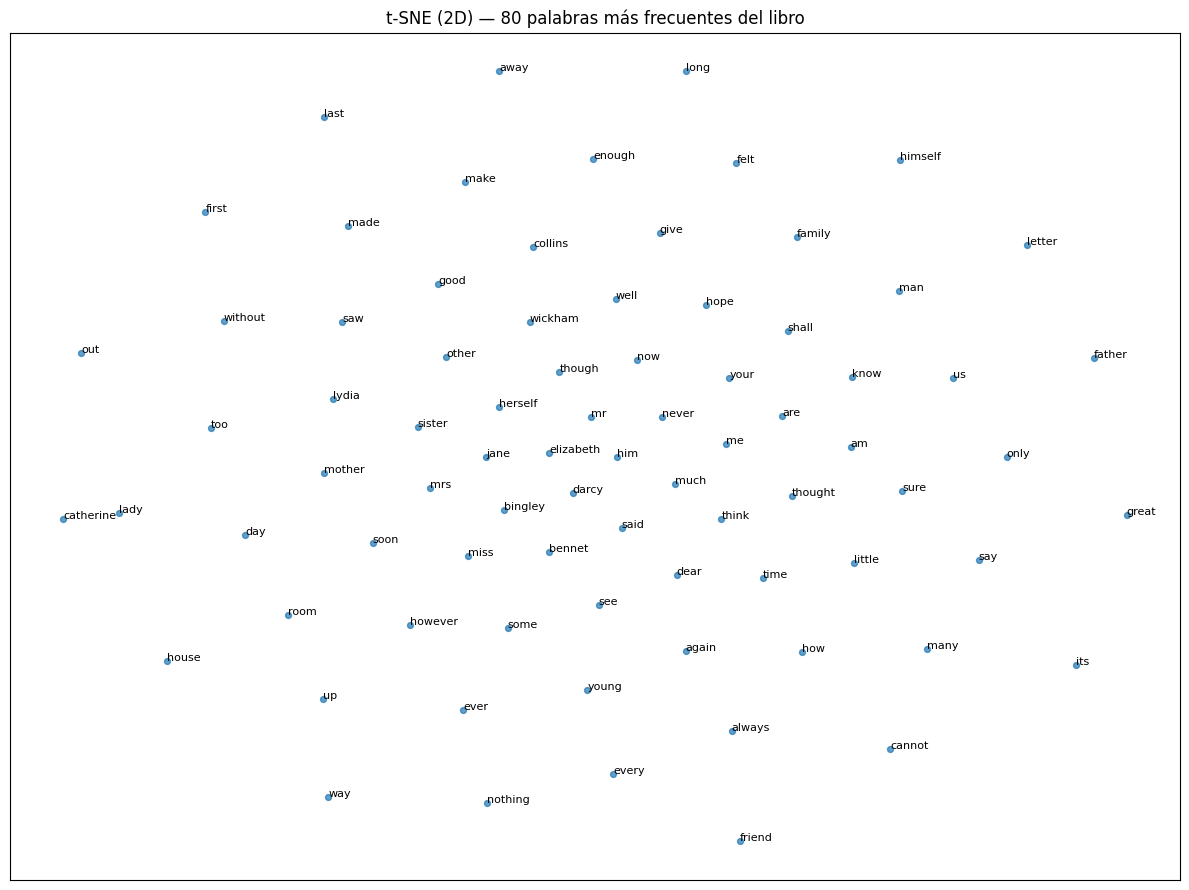

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

MAX_WORDS = 80


def reducir_tsne(model, n=2, palabras=None):
    if palabras is None:
        palabras = list(model.wv.index_to_key[:MAX_WORDS])
    palabras = [w for w in palabras if w in model.wv]
    M = np.vstack([model.wv.get_vector(w) for w in palabras])
    xy = TSNE(n_components=n, random_state=42, perplexity=min(30, len(palabras) - 1)).fit_transform(M)
    return xy, palabras


xy, labels = reducir_tsne(w2v_libro)

fig, ax = plt.subplots(figsize=(12, 9))
ax.scatter(xy[:, 0], xy[:, 1], s=18, alpha=0.7)
for (x, y), w in zip(xy, labels):
    ax.annotate(w, (x, y), fontsize=8)
ax.set_title("t-SNE (2D) — 80 palabras más frecuentes del libro")
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.show()


### 5. Inspección de clusters

Se colorean tres grupos armados a mano (personajes, familia, matrimonio) sobre **un único** t-SNE: las 80 más frecuentes más esas palabras si no estaban en el top. Así gris y colores comparten coordenadas. La figura de la celda siguiente hace de captura.


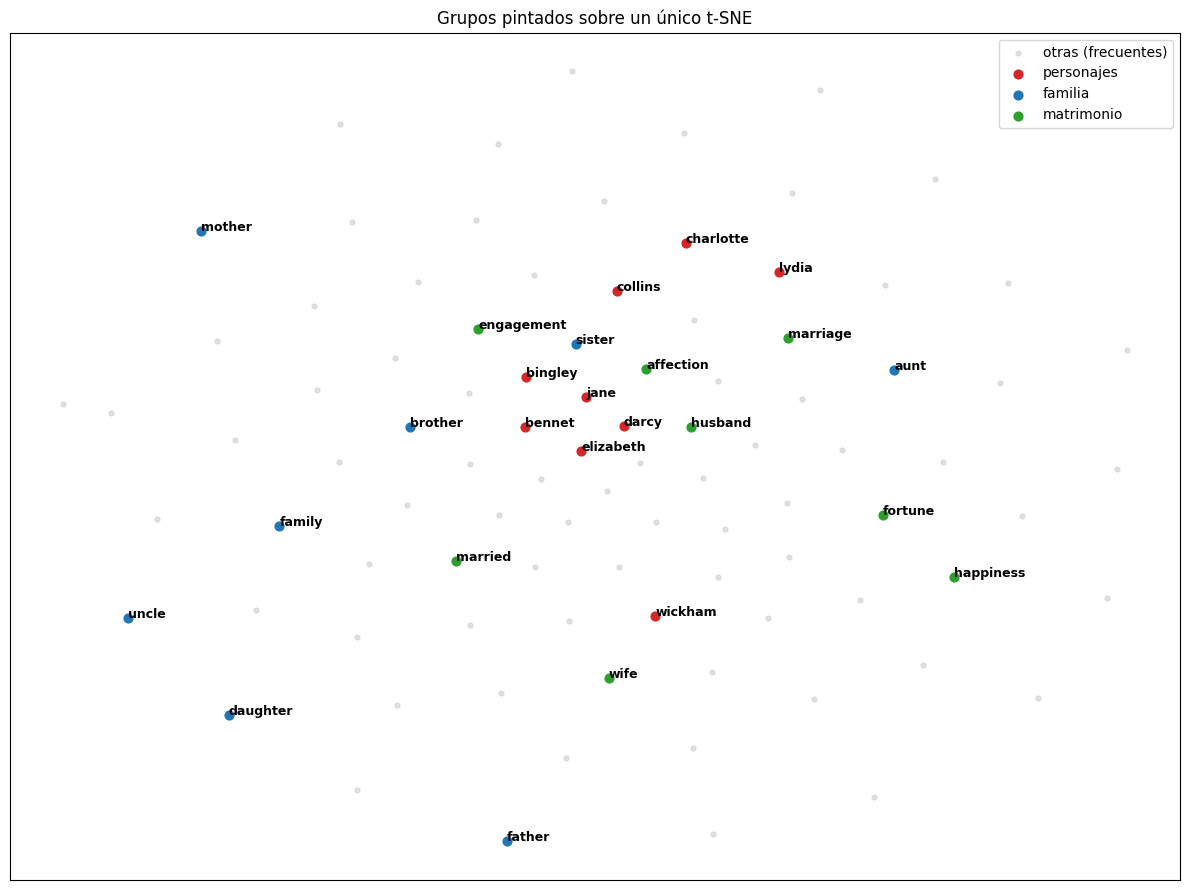

In [33]:
grupos = {
    "personajes": ["elizabeth", "jane", "lydia", "darcy", "bingley", "wickham", "collins", "charlotte", "bennet"],
    "familia": ["sister", "mother", "father", "family", "aunt", "uncle", "brother", "daughter"],
    "matrimonio": ["marriage", "married", "husband", "wife", "fortune", "engagement", "affection", "happiness"],
}

palette = {"personajes": "tab:red", "familia": "tab:blue", "matrimonio": "tab:green"}
palabra_a_grupo = {}
for nombre, lista in grupos.items():
    for w in lista:
        if w in w2v_libro.wv:
            palabra_a_grupo[w] = nombre

fondo = [w for w in w2v_libro.wv.index_to_key[:MAX_WORDS] if w not in palabra_a_grupo]
palabras_plot = fondo + [w for w in palabra_a_grupo if w not in fondo]

xy, labels = reducir_tsne(w2v_libro, palabras=palabras_plot)
coords = {w: xy[i] for i, w in enumerate(labels)}

fig, ax = plt.subplots(figsize=(12, 9))
xy_fondo = np.vstack([coords[w] for w in fondo])
ax.scatter(xy_fondo[:, 0], xy_fondo[:, 1], s=12, c="lightgray", alpha=0.7, label="otras (frecuentes)")

for grupo, color in palette.items():
    ws = [w for w, g in palabra_a_grupo.items() if g == grupo]
    ax.scatter(
        [coords[w][0] for w in ws],
        [coords[w][1] for w in ws],
        s=40, c=color, label=grupo, zorder=3,
    )
    for w in ws:
        ax.annotate(w, coords[w], fontsize=9, fontweight="bold", zorder=4)

ax.legend()
ax.set_title("Grupos pintados sobre un único t-SNE")
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.show()


**Interpretación**

**Las 80 más frecuentes.** No se forman blobs temáticos. t-SNE reparte palabras muy frecuentes (diálogos: `said`, `know`, `think`; resto: `however`, `never`, `much`). Eso no es un fallo de `MAX_WORDS=80`: esas palabras aparecen en muchos contextos y el vector queda “promedio”.

Sí se ven vecindarios **suaves**:
- centro: `elizabeth`, `jane`, `darcy`, `bingley`, `bennet`, con `mr` / `miss` / `said`;
- izquierda: `lady` junto a `catherine` (dos tokens que viajan juntos);
- `lydia` cerca de `sister` / `mother`;
- `father` lejos de `mother` / `family`.

No se lee como cluster de hermanas ni de matrimonio: en este recorte casi no hay vocabulario de casamiento (`marriage`, `husband`, … no están entre las 80).

**Grupos pintados (mismo t-SNE).** El gris es ese fondo frecuente. Rojo / azul / verde son listas elegidas a mano; varias (p. ej. `marriage`, `charlotte`) están fuera del top 80 y se agregan al mismo espacio. Si un color no se junta, no se fuerza una escena: la proyección 2D deforma distancias. La evidencia más estable sigue siendo `most_similar` (`pride`–`prejudice`, `wickham`–`george`, `jane`–`elizabeth`).

**Conclusión.** En un solo libro Word2Vec deja vecindarios blandos y collocations (título, nombre+apellido, `lady`+`catherine`). El gráfico sirve para inspeccionar, no como prueba de clusters. El valor del experimento es contrastar lo que se eligió a mano con lo que el modelo imprimió.
